In [3]:
import numpy as nd
import pandas as pd
df = pd.read_csv("Iris.csv")
print(df.head())
print(df.columns)
print(df.shape)

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')
(150, 6)


In [4]:
print(df.isnull().sum())

Id               0
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64


In [5]:
x = df[["SepalLengthCm","SepalWidthCm","PetalLengthCm","PetalWidthCm"]]

## K mean

In [13]:
from sklearn.cluster import KMeans

KMean = KMeans(n_clusters=3, random_state=42)

KMean.fit(x)

predicted_cluster = KMean.labels_

print(predicted_cluster)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 0 0 0 2 0 0 0 0
 0 0 2 2 0 0 0 0 2 0 2 0 2 0 0 2 2 0 0 0 0 0 2 0 0 0 0 2 0 0 0 2 0 0 0 2 0
 0 2]


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


## visualize the clusters

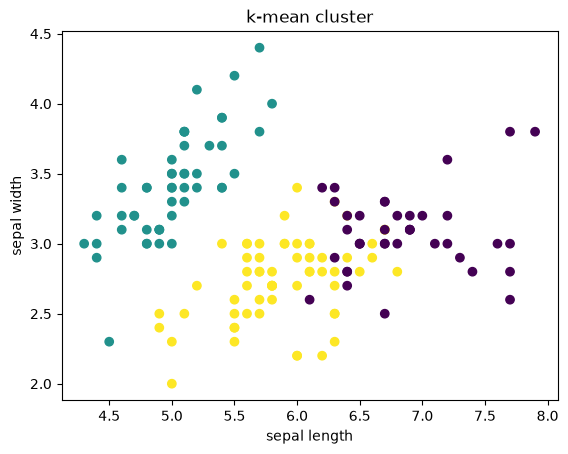

In [19]:
import matplotlib.pyplot as plt

plt.scatter(x['SepalLengthCm'], 
x['SepalWidthCm'],
c=predicted_cluster)

plt.xlabel('sepal length')
plt.ylabel('sepal width')
plt.title('k-mean cluster')

plt.show()

## Compare predicted cluster VS true labels

In [21]:
comparision = pd.DataFrame({'True species': df['Species'],
                            'Predicted cluster': predicted_cluster})
print(comparision.head(20))

   True species  Predicted cluster
0   Iris-setosa                  1
1   Iris-setosa                  1
2   Iris-setosa                  1
3   Iris-setosa                  1
4   Iris-setosa                  1
5   Iris-setosa                  1
6   Iris-setosa                  1
7   Iris-setosa                  1
8   Iris-setosa                  1
9   Iris-setosa                  1
10  Iris-setosa                  1
11  Iris-setosa                  1
12  Iris-setosa                  1
13  Iris-setosa                  1
14  Iris-setosa                  1
15  Iris-setosa                  1
16  Iris-setosa                  1
17  Iris-setosa                  1
18  Iris-setosa                  1
19  Iris-setosa                  1


In [22]:
comparision = pd.crosstab(df['Species'], predicted_cluster)
print(comparision)

col_0             0   1   2
Species                    
Iris-setosa       0  50   0
Iris-versicolor   3   0  47
Iris-virginica   36   0  14
